## 10. Final Testing — SVM Classification

## Objective

This notebook performs the final evaluation of the selected Support Vector Machine (SVM) model using the June 2026 test dataset.

The **Optimized RBF SVM** was selected based on its validation performance during the hyperparameter optimization process.

The final testing stage evaluates the model's generalization performance on previously unseen data. The test dataset is not used for model training, hyperparameter tuning, or model selection.

### Final Model Configuration
- Model: Support Vector Machine (SVM)
- Kernel: RBF
- C: 10
- Gamma: 0.01
- Training period: January–April 2026
- Validation period: May 2026
- Testing period: June 2026

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

FEATURES = [
    "hour_of_day",
    "day_of_week",
    "month",
    "is_weekend",
    "is_holiday",
    "is_major_nyc_event",
    "PU_longitude",
    "PU_latitude",
    "is_airport",
    "is_cbd",
    "lag_1",
    "lag_24",
    "lag_168",
    "roll_24",
    "roll_168"
]

TARGET = "demand_level"

print("Imports and configuration completed.")
print("Number of features:", len(FEATURES))
print("Target:", TARGET)

Imports and configuration completed.
Number of features: 15
Target: demand_level


## Test Dataset Preparation

The final testing process uses the June 2026 test set. The dataset is loaded from the previously prepared feature dataset, ensuring that the same feature structure and target definition are used throughout the experiment.

Only observations belonging to the test split are selected for the final evaluation.

In [2]:
data_path_candidates = [
    Path("../datasets/interim/2026/features_dataset.parquet"),
    Path("datasets/interim/2026/features_dataset.parquet"),
    Path("../../datasets/interim/2026/features_dataset.parquet")
]

data_path = next(
    (path for path in data_path_candidates if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "features_dataset.parquet not found. "
        "Please check the notebook working directory."
    )

df = pd.read_parquet(data_path)

print("Dataset loaded successfully!")
print("Dataset path:", data_path)
print("Dataset shape:", df.shape)

print("\nSplit distribution:")
print(df["split"].value_counts())

# Select June test set
test_df = df[df["split"] == "test"].copy()

print("\nTest dataset shape:", test_df.shape)

# Verify required columns
required_columns = FEATURES + [TARGET, "split"]

missing_columns = [
    col for col in required_columns
    if col not in test_df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Remove rows with missing values in required features/target
test_df = test_df.dropna(subset=FEATURES + [TARGET]).copy()

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("\nTest set preparation completed.")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTest target distribution:")
print(y_test.value_counts())

Dataset loaded successfully!
Dataset path: ..\datasets\interim\2026\features_dataset.parquet
Dataset shape: (1053841, 22)

Split distribution:
split
train         668809
validation    195672
test          189360
Name: count, dtype: int64

Test dataset shape: (189360, 22)

Test set preparation completed.
X_test shape: (189360, 15)
y_test shape: (189360,)

Test target distribution:
demand_level
Rendah    93217
Tinggi    52347
Sedang    43796
Name: count, dtype: int64


## Final Model Reconstruction

The selected model configuration is reconstructed using the training data and the optimized hyperparameters obtained during validation.

The model uses an RBF kernel with C = 10 and gamma = 0.01. The June test data is reserved exclusively for final performance evaluation.

No hyperparameter tuning is performed in this notebook.

In [3]:
# ==========================================
# RECONSTRUCT FINAL OPTIMIZED RBF SVM
# ==========================================

# Select training data only
train_df = df[df["split"] == "train"].copy()

# Balanced sampling: maximum 5,000 samples per class
rbf_final_parts = []

for label in train_df[TARGET].unique():

    class_group = train_df[train_df[TARGET] == label]

    sampled_group = class_group.sample(
        n=min(len(class_group), 5000),
        random_state=42
    )

    rbf_final_parts.append(sampled_group)

rbf_final_train = pd.concat(
    rbf_final_parts,
    ignore_index=True
)

X_train_final = rbf_final_train[FEATURES]
y_train_final = rbf_final_train[TARGET]

print("Final training sample:", X_train_final.shape)
print("\nTraining class distribution:")
print(y_train_final.value_counts())

# Final optimized RBF model
final_rbf_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=10,
        gamma=0.01,
        class_weight="balanced"
    ))
])

# Train final model
start_train = time.time()

final_rbf_model.fit(
    X_train_final,
    y_train_final
)

final_training_time = time.time() - start_train

print("\nFinal RBF model training completed!")
print(f"Training time: {final_training_time:.2f} seconds")

Final training sample: (15000, 15)

Training class distribution:
demand_level
Rendah    5000
Sedang    5000
Tinggi    5000
Name: count, dtype: int64

Final RBF model training completed!
Training time: 6.73 seconds


## Final Evaluation on June Test Set

The trained Optimized RBF SVM is evaluated on the June 2026 test dataset.

The evaluation reports Accuracy, Macro Precision, Macro Recall, and Macro F1-score. A classification report and confusion matrix are also generated to examine the model's performance across demand categories.

These results represent the final generalization performance of the selected model on unseen data.

In [4]:
# ==========================================
# FINAL TEST EVALUATION - JUNE 2026
# ==========================================

# Prediction
start_evaluation = time.time()

y_test_pred = final_rbf_model.predict(X_test)

final_evaluation_time = time.time() - start_evaluation

# Metrics
final_accuracy = accuracy_score(y_test, y_test_pred)

final_precision_macro = precision_score(
    y_test,
    y_test_pred,
    average="macro"
)

final_recall_macro = recall_score(
    y_test,
    y_test_pred,
    average="macro"
)

final_f1_macro = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)

# Results
print("=" * 50)
print("FINAL TEST RESULTS - JUNE 2026")
print("=" * 50)

print(f"Accuracy       : {final_accuracy:.4f}")
print(f"Precision Macro: {final_precision_macro:.4f}")
print(f"Recall Macro   : {final_recall_macro:.4f}")
print(f"Macro F1      : {final_f1_macro:.4f}")
print(f"Training Time  : {final_training_time:.2f} seconds")
print(f"Testing Time   : {final_evaluation_time:.2f} seconds")

FINAL TEST RESULTS - JUNE 2026
Accuracy       : 0.7812
Precision Macro: 0.7625
Recall Macro   : 0.7491
Macro F1      : 0.7551
Training Time  : 6.73 seconds
Testing Time   : 179.50 seconds


In [5]:
# ==========================================
# CLASSIFICATION REPORT
# ==========================================

print("FINAL CLASSIFICATION REPORT - JUNE 2026")

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=["Rendah", "Sedang", "Tinggi"],
        digits=4,
        zero_division=0
    )
)

FINAL CLASSIFICATION REPORT - JUNE 2026
              precision    recall  f1-score   support

      Rendah     0.8041    0.8493    0.8261     93217
      Sedang     0.5359    0.5163    0.5259     43796
      Tinggi     0.9475    0.8815    0.9133     52347

    accuracy                         0.7812    189360
   macro avg     0.7625    0.7491    0.7551    189360
weighted avg     0.7817    0.7812    0.7808    189360



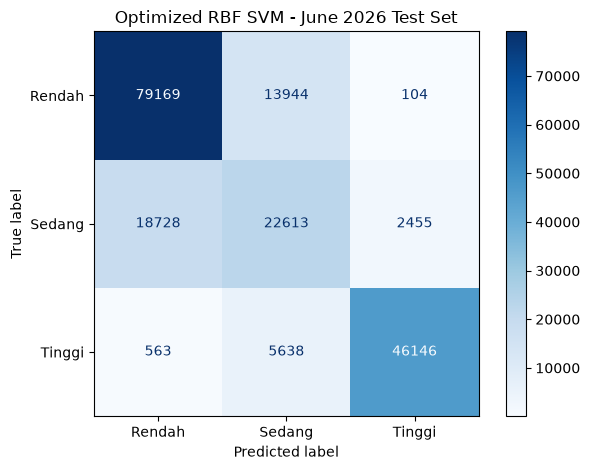

In [6]:
# ==========================================
# CONFUSION MATRIX - FINAL TEST
# ==========================================

cm_final = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["Rendah", "Sedang", "Tinggi"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["Rendah", "Sedang", "Tinggi"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Optimized RBF SVM - June 2026 Test Set")
plt.tight_layout()
plt.show()

In [7]:
# ==========================================
# FINAL RESULTS SUMMARY TABLE
# ==========================================

final_results_df = pd.DataFrame([{
    "Model": "Optimized RBF SVM",
    "Kernel": "RBF",
    "C": 10,
    "Gamma": 0.01,
    "Accuracy": final_accuracy,
    "Precision Macro": final_precision_macro,
    "Recall Macro": final_recall_macro,
    "Macro F1": final_f1_macro,
    "Training Time (s)": final_training_time,
    "Evaluation Time (s)": final_evaluation_time
}])

display(final_results_df)

,Model,Kernel,C,Gamma,Accuracy,Precision Macro,Recall Macro,Macro F1,Training Time (s),Evaluation Time (s)
0,Optimized RBF SVM,RBF,10,0.01,0.7812,0.762483,0.749055,0.755106,6.72857,179.5041


In [8]:
# ==========================================
# SAVE FINAL TEST RESULTS
# ==========================================

output_candidates = [
    Path("../out"),
    Path("out"),
    Path("../../out")
]

output_dir = next(
    (path for path in output_candidates if path.exists()),
    Path("../out")
)

output_dir.mkdir(parents=True, exist_ok=True)

final_results_df.to_csv(
    output_dir / "svm_final_test_results_june.csv",
    index=False
)

pd.DataFrame(
    classification_report(
        y_test,
        y_test_pred,
        labels=["Rendah", "Sedang", "Tinggi"],
        output_dict=True,
        zero_division=0
    )
).transpose().to_csv(
    output_dir / "svm_final_classification_report_june.csv"
)

pd.DataFrame(
    cm_final,
    index=["Actual Rendah", "Actual Sedang", "Actual Tinggi"],
    columns=["Predicted Rendah", "Predicted Sedang", "Predicted Tinggi"]
).to_csv(
    output_dir / "svm_final_confusion_matrix_june.csv"
)

print("Final testing results saved to:", output_dir.resolve())

Final testing results saved to: C:\IF SEM 5\Data Science Teori\Cooked-DS-Final-Project\out


# Conclusion

The Optimized RBF SVM was selected as the final model based on its validation performance. The model was configured with C = 10 and gamma = 0.01.

Final testing was conducted using the June 2026 test dataset, which was excluded from the training and hyperparameter optimization processes.

The final test results demonstrate the model's ability to classify taxi demand into Low, Medium, and High demand categories on unseen data.

The final performance is evaluated using Accuracy, Macro Precision, Macro Recall, and Macro F1-score. The classification report and confusion matrix provide further insights into the model's performance across individual demand categories.

The results of the June test set are used as the final assessment of the model's generalization performance.